   # CMS Hospital Quality Analysis
   **Research questions**
   1. RQ1: How do readmissions and penalties differ by hospital characteristics?
   2. RQ2: Do hospitals with better patient experience have fewer excess readmissions?
   3. RQ3: Which hospital characteristics are associated with a HAC payment reduction?

   Data: 3,035 acute care hospitals (CMS FY2026), exported from SQL Server view `v_hospital_analysis`.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import statsmodels

print("pandas", pd.__version__)
print("seaborn", sns.__version__)
print("scipy", scipy.__version__)
print("statsmodels", statsmodels.__version__)

pandas 1.4.4
seaborn 0.11.2
scipy 1.9.1
statsmodels 0.13.2


In [8]:
df = pd.read_csv("../Data Processed/hospital_analysis.txt",
                 sep="\t",
                 dtype={"facility_id": str},
                 na_values="NULL")

print(df.shape)
df.head()

(3035, 46)


,facility_id,facility_name,city,state,census_region,hospital_type,hospital_ownership,ownership_group,emergency_services,birthing_friendly,...,safety_score,efficiency_score,total_performance_score,nurse_comm_rate,doctor_comm_rate,care_transition_rate,discharge_info_rate,overall_rating_rate,hcahps_base_score,hcahps_consistency_score
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,DOTHAN,AL,South,Acute Care Hospitals,Government - Hospital District or Authority,Government,1,1,...,51.6667,10.0,32.1667,74.6272,81.0814,55.1296,86.9136,74.5772,25.0,18.0
1,010005,MARSHALL MEDICAL CENTERS,BOAZ,AL,South,Acute Care Hospitals,Government - Hospital District or Authority,Government,1,1,...,31.6667,10.0,20.9167,77.9676,83.5923,47.6615,87.5786,70.9775,24.0,13.0
2,010006,NORTH ALABAMA MEDICAL CENTER,FLORENCE,AL,South,Acute Care Hospitals,Proprietary,For-profit,1,1,...,85.0000,0.0,25.8333,75.1980,73.9352,41.8217,82.4038,60.9449,3.0,12.0
3,010007,MIZELL MEMORIAL HOSPITAL,OPP,AL,South,Acute Care Hospitals,Voluntary non-profit - Private,Nonprofit,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,010011,ST. VINCENT'S EAST,BIRMINGHAM,AL,South,Acute Care Hospitals,Voluntary non-profit - Private,Nonprofit,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3035 entries, 0 to 3034
Data columns (total 46 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   facility_id                   3035 non-null   object 
 1   facility_name                 3035 non-null   object 
 2   city                          3035 non-null   object 
 3   state                         3035 non-null   object 
 4   census_region                 3035 non-null   object 
 5   hospital_type                 3035 non-null   object 
 6   hospital_ownership            3035 non-null   object 
 7   ownership_group               3035 non-null   object 
 8   emergency_services            3035 non-null   int64  
 9   birthing_friendly             3035 non-null   int64  
 10  overall_star_rating           2654 non-null   float64
 11  in_hrrp                       3035 non-null   int64  
 12  in_hac                        3035 non-null   int64  
 13  in_

In [10]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)

missing_table = pd.DataFrame({"missing": missing, "pct_missing": missing_pct})
missing_table[missing_table["missing"] > 0].sort_values("pct_missing", ascending=False)

,missing,pct_missing
err_cabg,2158,71.1
err_hip_knee,1591,52.4
err_ami,1303,42.9
mrsa_sir,972,32.0
clabsi_sir,858,28.3
ssi_sir,772,25.4
err_copd,717,23.6
cauti_sir,687,22.6
clinical_outcomes_score,657,21.6
safety_score,644,21.2


In [6]:
key_vars = ["avg_err", "total_hac_score", "total_performance_score",
            "discharge_info_rate", "care_transition_rate",
            "hcahps_base_score", "overall_star_rating"]

df[key_vars].describe().round(3)

,avg_err,total_hac_score,total_performance_score,discharge_info_rate,care_transition_rate,hcahps_base_score,overall_star_rating
count,2818.000,2917.000,2446.000,2415.000,2415.000,2415.000,2654.000
mean,0.999,0.006,30.872,85.803,49.556,21.626,3.170
std,0.057,0.636,11.635,3.560,5.638,16.671,1.083
min,0.552,-1.473,0.000,66.863,28.366,0.000,1.000
25%,0.973,-0.417,22.333,83.776,46.187,9.000,2.000
50%,1.000,-0.044,29.500,86.293,49.707,18.000,3.000
75%,1.028,0.379,37.698,88.218,53.224,31.000,4.000
max,1.310,2.313,94.667,98.608,85.734,80.000,5.000


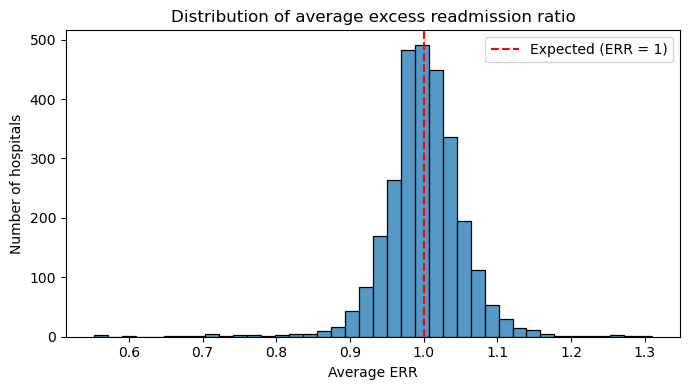

In [11]:
plt.figure(figsize=(7, 4))
sns.histplot(df["avg_err"].dropna(), bins=40)
plt.axvline(1, color="red", linestyle="--", label="Expected (ERR = 1)")
plt.title("Distribution of average excess readmission ratio")
plt.xlabel("Average ERR")
plt.ylabel("Number of hospitals")
plt.legend()
plt.tight_layout()
plt.savefig("../Reports/fig1_err_distribution.png", dpi=150)
plt.show()

In [12]:
from scipy import stats

rq2 = df[["discharge_info_rate", "care_transition_rate",
          "hcahps_base_score", "avg_err"]].dropna()
print("Hospitals in RQ2 analysis:", len(rq2))

for col in ["discharge_info_rate", "care_transition_rate", "hcahps_base_score"]:
    rho, p = stats.spearmanr(rq2[col], rq2["avg_err"])
    print(f"{col}: rho = {rho:.3f}, p-value = {p:.4g}")

Hospitals in RQ2 analysis: 2383
discharge_info_rate: rho = -0.266, p-value = 5.403e-40
care_transition_rate: rho = -0.212, p-value = 1.507e-25
hcahps_base_score: rho = -0.188, p-value = 1.822e-20


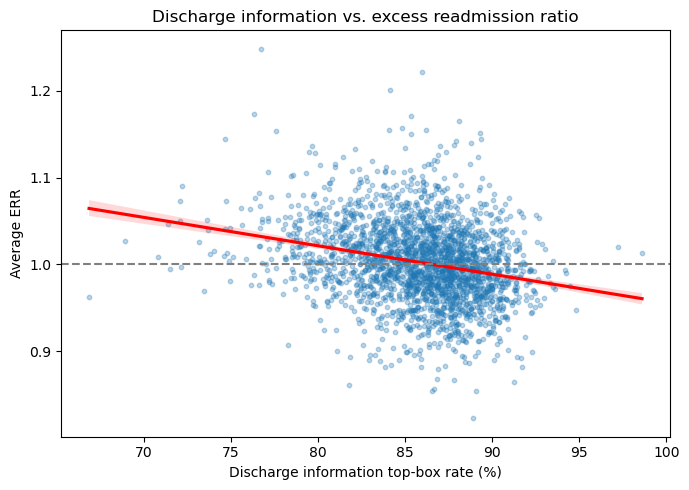

In [13]:
plt.figure(figsize=(7, 5))
sns.regplot(data=rq2, x="discharge_info_rate", y="avg_err",
            scatter_kws={"alpha": 0.3, "s": 10}, line_kws={"color": "red"})
plt.axhline(1, color="gray", linestyle="--")
plt.title("Discharge information vs. excess readmission ratio")
plt.xlabel("Discharge information top-box rate (%)")
plt.ylabel("Average ERR")
plt.tight_layout()
plt.savefig("../Reports/fig2_discharge_vs_err.png", dpi=150)
plt.show()

### RQ2 finding
Discharge information scores were negatively correlated with excess readmission ratios (Spearman ρ = −0.27, p < 0.001, n = 2,383). Care transition (ρ = −0.21) and overall HCAHPS scores (ρ = −0.19) showed similar but weaker associations.

In [14]:
import statsmodels.formula.api as smf

rq2_df = df.dropna(subset=["avg_err", "discharge_info_rate", "total_hrrp_discharges"]).copy()
rq2_df["log_discharges"] = np.log1p(rq2_df["total_hrrp_discharges"])

rq2_model = smf.ols(
    "avg_err ~ discharge_info_rate + C(ownership_group) + C(census_region) + log_discharges",
    data=rq2_df
).fit()

print("Hospitals in model:", len(rq2_df))
print(rq2_model.summary())

Hospitals in model: 2248
                            OLS Regression Results                            
Dep. Variable:                avg_err   R-squared:                       0.086
Model:                            OLS   Adj. R-squared:                  0.083
Method:                 Least Squares   F-statistic:                     30.23
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           3.49e-40
Time:                        20:10:16   Log-Likelihood:                 3802.8
No. Observations:                2248   AIC:                            -7590.
Df Residuals:                    2240   BIC:                            -7544.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------

### RQ2 regression (controlling for ownership, region, size)
After adjusting for ownership, region, and hospital volume, each 1-point increase in discharge information score was associated with a 0.003 lower excess readmission ratio (95% CI −0.004 to −0.002, p < 0.001, n = 2,248), about 3% fewer readmissions than expected per 10 points. The model explained 8.6% of variation (R² = 0.086), indicating that patient experience is one of several factors. Results were unchanged using heteroskedasticity-robust (HC3) standard errors.

In [15]:
rq2_robust = smf.ols(
    "avg_err ~ discharge_info_rate + C(ownership_group) + C(census_region) + log_discharges",
    data=rq2_df
).fit(cov_type="HC3")

print(rq2_robust.summary().tables[1])

                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                            1.2601      0.025     49.529      0.000       1.210       1.310
C(ownership_group)[T.Government]    -0.0049      0.003     -1.478      0.139      -0.011       0.002
C(ownership_group)[T.Nonprofit]     -0.0095      0.003     -3.556      0.000      -0.015      -0.004
C(census_region)[T.Northeast]        0.0085      0.003      2.621      0.009       0.002       0.015
C(census_region)[T.South]            0.0010      0.002      0.393      0.695      -0.004       0.006
C(census_region)[T.West]            -0.0127      0.003     -4.382      0.000      -0.018      -0.007
discharge_info_rate                 -0.0030      0.000    -10.319      0.000      -0.004      -0.002
log_discharges                       0.0013      0.001      1.746      0.081      -0.000   

In [16]:
rq3_df = df[df["total_hac_score"].notna() & df["hac_payment_reduction"].notna()].copy()
rq3_df = rq3_df.dropna(subset=["total_hrrp_discharges", "emergency_services"])
rq3_df["log_discharges"] = np.log1p(rq3_df["total_hrrp_discharges"])
rq3_df["star_cat"] = rq3_df["overall_star_rating"].map(
    lambda x: "No rating" if pd.isna(x) else f"{int(x)} star")

print("Hospitals in RQ3:", len(rq3_df))
print("Penalized:", int(rq3_df["hac_payment_reduction"].sum()))
print(rq3_df["emergency_services"].value_counts())

model_a = smf.logit(
    "hac_payment_reduction ~ C(ownership_group) + C(census_region) + log_discharges + emergency_services",
    data=rq3_df
).fit()

def odds_table(m):
    ci = m.conf_int()
    return pd.DataFrame({
        "odds_ratio": np.exp(m.params),
        "ci_low": np.exp(ci[0]),
        "ci_high": np.exp(ci[1]),
        "p_value": m.pvalues
    }).round(3)

print("Pseudo R-squared:", round(model_a.prsquared, 3))
odds_table(model_a)

Hospitals in RQ3: 2494
Penalized: 620
1    2351
0     143
Name: emergency_services, dtype: int64
Optimization terminated successfully.
         Current function value: 0.547750
         Iterations 6
Pseudo R-squared: 0.023


,odds_ratio,ci_low,ci_high,p_value
Intercept,0.359,0.202,0.636,0.000
C(ownership_group)[T.Government],3.088,2.204,4.329,0.000
C(ownership_group)[T.Nonprofit],1.945,1.472,2.569,0.000
C(census_region)[T.Northeast],1.152,0.867,1.532,0.329
C(census_region)[T.South],0.836,0.654,1.068,0.152
C(census_region)[T.West],0.962,0.727,1.272,0.784
log_discharges,0.892,0.840,0.948,0.000
emergency_services,1.065,0.711,1.594,0.761


### RQ3 Model A: HAC penalty (without star rating)
In a logistic regression of 2,494 hospitals (620 penalized), government hospitals had about three times the odds of a HAC payment reduction compared with for-profit hospitals (OR = 3.09, 95% CI 2.20–4.33, p < 0.001), and nonprofit hospitals about twice the odds (OR = 1.95, 95% CI 1.47–2.57). Larger hospitals had lower odds (OR = 0.89 per log-unit of discharges, p < 0.001). Region and emergency services were not significant. Overall explanatory power was low (pseudo R² = 0.023).

In [17]:
model_b = smf.logit(
    "hac_payment_reduction ~ C(ownership_group) + C(census_region) + log_discharges + emergency_services"
    " + C(star_cat, Treatment('3 star'))",
    data=rq3_df
).fit()

print("Pseudo R-squared - Model A:", round(model_a.prsquared, 3))
print("Pseudo R-squared - Model B:", round(model_b.prsquared, 3))
odds_table(model_b)

Optimization terminated successfully.
         Current function value: 0.500016
         Iterations 7
Pseudo R-squared - Model A: 0.023
Pseudo R-squared - Model B: 0.108


,odds_ratio,ci_low,ci_high,p_value
Intercept,0.282,0.142,0.560,0.000
C(ownership_group)[T.Government],3.444,2.413,4.915,0.000
C(ownership_group)[T.Nonprofit],2.889,2.144,3.893,0.000
C(census_region)[T.Northeast],0.974,0.719,1.320,0.865
C(census_region)[T.South],0.750,0.579,0.972,0.029
C(census_region)[T.West],0.922,0.686,1.239,0.589
"C(star_cat, Treatment('3 star'))[T.1 star]",4.391,3.020,6.385,0.000
"C(star_cat, Treatment('3 star'))[T.2 star]",2.518,1.962,3.233,0.000
"C(star_cat, Treatment('3 star'))[T.4 star]",0.590,0.452,0.770,0.000
"C(star_cat, Treatment('3 star'))[T.5 star]",0.230,0.138,0.383,0.000


### RQ3 Model B: adding star rating
Adding CMS star rating increased explanatory power substantially (pseudo R² 0.023 → 0.108), partly because star ratings include overlapping safety measures. Compared with 3-star hospitals, 1-star hospitals had 4.4 times the odds of a HAC penalty and 5-star hospitals 77% lower odds. Notably, the ownership effect strengthened rather than weakened (Government OR 3.09 → 3.44; Nonprofit OR 1.95 → 2.89), indicating that the higher penalty rates of government and nonprofit hospitals are not explained by lower overall quality ratings. A cross-tabulation confirmed a suppression effect: nonprofit hospitals had higher star ratings than for-profit hospitals (45% vs. 24% rated 4–5 stars) yet more HAC penalties, so the ownership gap widened once star rating was held constant.

In [18]:
pd.crosstab(rq3_df["ownership_group"], rq3_df["star_cat"], normalize="index").round(3) * 100

star_cat,1 star,2 star,3 star,4 star,5 star,No rating
ownership_group,,,,,,
For-profit,9.1,30.8,27.5,19.2,4.9,8.5
Government,10.4,28.8,29.1,20.9,7.3,3.5
Nonprofit,4.6,17.4,32.6,31.9,12.7,0.7


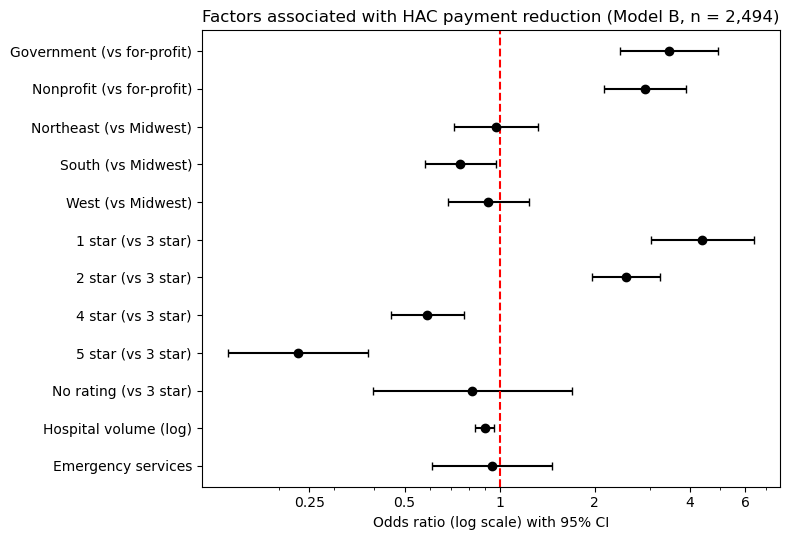

In [19]:
or_b = odds_table(model_b).drop("Intercept")

labels = {
    "C(ownership_group)[T.Government]": "Government (vs for-profit)",
    "C(ownership_group)[T.Nonprofit]": "Nonprofit (vs for-profit)",
    "C(census_region)[T.Northeast]": "Northeast (vs Midwest)",
    "C(census_region)[T.South]": "South (vs Midwest)",
    "C(census_region)[T.West]": "West (vs Midwest)",
    "C(star_cat, Treatment('3 star'))[T.1 star]": "1 star (vs 3 star)",
    "C(star_cat, Treatment('3 star'))[T.2 star]": "2 star (vs 3 star)",
    "C(star_cat, Treatment('3 star'))[T.4 star]": "4 star (vs 3 star)",
    "C(star_cat, Treatment('3 star'))[T.5 star]": "5 star (vs 3 star)",
    "C(star_cat, Treatment('3 star'))[T.No rating]": "No rating (vs 3 star)",
    "log_discharges": "Hospital volume (log)",
    "emergency_services": "Emergency services",
}
or_b.index = [labels.get(i, i) for i in or_b.index]

y = range(len(or_b))
plt.figure(figsize=(8, 5.5))
plt.errorbar(or_b["odds_ratio"], y,
             xerr=[or_b["odds_ratio"] - or_b["ci_low"], or_b["ci_high"] - or_b["odds_ratio"]],
             fmt="o", color="black", capsize=3)
plt.axvline(1, color="red", linestyle="--")
plt.xscale("log")
plt.xticks([0.25, 0.5, 1, 2, 4, 6], ["0.25", "0.5", "1", "2", "4", "6"])
plt.yticks(y, or_b.index)
plt.gca().invert_yaxis()
plt.xlabel("Odds ratio (log scale) with 95% CI")
plt.title("Factors associated with HAC payment reduction (Model B, n = 2,494)")
plt.tight_layout()
plt.savefig("../Reports/fig3_rq3_odds_ratios.png", dpi=150)
plt.show()